# 04 · Vendedores e produtos

O notebook 03 mostrou que o atraso derruba a nota, mas que **dois terços das notas 1 e 2 vêm de pedidos entregues no prazo**. Para um investidor, a questão passa a ser onde agir. A pergunta que guia este notebook é

> **Onde estão os atrasos e as notas ruins: em quais rotas, vendedores e produtos?**

Três tabelas entram aqui: vendedores (sellers), com o estado de cada vendedor, produtos (products), com a categoria, e a tradução das categorias para o inglês.

## 6.1 Leitura das tabelas

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

AZUL, LARANJA, CINZA = '#2a78d6', '#eb6834', '#a3a29d'
plt.rcParams.update({
    'figure.figsize': (10, 4), 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#a3a29d', 'axes.titlesize': 12, 'axes.titleweight': 'bold',
    'axes.titlelocation': 'left', 'axes.grid': True, 'axes.axisbelow': True,
    'grid.color': '#e6e5e0', 'grid.linewidth': 0.8, 'axes.grid.axis': 'y',
})

orders = pd.read_csv('../data/raw/olist_orders_dataset.csv')
for coluna in ['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date',
               'order_delivered_customer_date', 'order_estimated_delivery_date']:
    orders[coluna] = pd.to_datetime(orders[coluna])

items = pd.read_csv('../data/raw/olist_order_items_dataset.csv')
items['shipping_limit_date'] = pd.to_datetime(items['shipping_limit_date'])
customers = pd.read_csv('../data/raw/olist_customers_dataset.csv')
reviews = pd.read_csv('../data/raw/olist_order_reviews_dataset.csv')
reviews['review_answer_timestamp'] = pd.to_datetime(reviews['review_answer_timestamp'])

sellers = pd.read_csv('../data/raw/olist_sellers_dataset.csv')
products = pd.read_csv('../data/raw/olist_products_dataset.csv')
traducao = pd.read_csv('../data/raw/product_category_name_translation.csv')

print('Vendedores:', sellers.shape)
print('Produtos:', products.shape)
print('Tradução:', traducao.shape)
sellers.head()

Vendedores: (3095, 4)
Produtos: (32951, 9)
Tradução: (71, 2)


,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


**3.095 vendedores** com CEP, cidade e estado; 32.951 produtos; e uma tabela de tradução com 71 categorias.

Antes de analisar, monto a base de pedidos entregues com as decisões dos notebooks anteriores: recorte de jan/2017 a ago/2018, só delivered com data de entrega, atraso comparado por dia, última avaliação respondida de cada pedido e o estado do cliente.

In [2]:
entregues = orders[(orders['order_status'] == 'delivered')
                   & orders['order_delivered_customer_date'].notna()
                   & orders['order_purchase_timestamp'].between('2017-01-01', '2018-08-31 23:59:59')].copy()
entregues['atrasado'] = entregues['order_delivered_customer_date'].dt.normalize() > entregues['order_estimated_delivery_date']
entregues['prazo'] = (entregues['order_delivered_customer_date']
                      - entregues['order_purchase_timestamp']).dt.total_seconds() / 86400

nota_pedido = (reviews.sort_values('review_answer_timestamp')
                      .drop_duplicates(subset='order_id', keep='last'))
entregues = entregues.merge(nota_pedido[['order_id', 'review_score', 'review_comment_message']], on='order_id', how='left')
entregues['nota_ruim'] = entregues['review_score'] <= 2
entregues = entregues.merge(customers[['customer_id', 'customer_state']], on='customer_id')

print(f'Pedidos entregues: {len(entregues):,} | atrasados: {entregues["atrasado"].mean() * 100:.1f}%')

Pedidos entregues: 96,203 | atrasados: 6.8%


Os mesmos 96.203 pedidos e 6,8% de atraso do notebook 03: a base está consistente.

## 6.2 Qualidade da tabela de vendedores

In [3]:
print('Vendedores distintos:', sellers['seller_id'].nunique())
print('Vazios:', sellers.isnull().sum().sum(), '| linhas idênticas:', sellers.duplicated().sum())
print('Vendedores sem item vendido:', (~sellers['seller_id'].isin(items['seller_id'])).sum())
print('Itens sem vendedor:', (~items['seller_id'].isin(sellers['seller_id'])).sum())
print()
print(sellers['seller_state'].value_counts().head(6))

Vendedores distintos: 3095
Vazios: 0 | linhas idênticas: 0
Vendedores sem item vendido: 0
Itens sem vendedor: 0

seller_state
SP    1849
PR     349
MG     244
SC     190
RJ     171
RS     129
Name: count, dtype: int64


- Um vendedor por linha, sem vazios, duplicatas ou órfãos.
- **1.849 dos 3.095 vendedores (60%) estão em SP.** Os vendedores estão em 23 estados, mas concentrados no Sul e Sudeste.

Um pedido pode ter itens de mais de um vendedor. Para ligar cada pedido a um vendedor, preciso saber quantos pedidos têm mais de um.

In [4]:
por_pedido = items.groupby('order_id').agg(itens=('order_item_id', 'size'),
                                           produtos=('product_id', 'nunique'),
                                           vendedores=('seller_id', 'nunique'),
                                           seller_id=('seller_id', 'first'),
                                           limite_postagem=('shipping_limit_date', 'max'))
print('Pedidos com mais de um vendedor:', (por_pedido['vendedores'] > 1).sum())

Pedidos com mais de um vendedor: 1278


Só **1.278 pedidos** (1,3%) têm mais de um vendedor.

**Decisão:** para rotas e estados, uso o vendedor do primeiro item do pedido. O erro fica restrito a esses 1,3%.

In [5]:
entregues = entregues.merge(por_pedido, on='order_id')
entregues = entregues.merge(sellers[['seller_id', 'seller_state']], on='seller_id')
print((entregues['seller_state'].value_counts(normalize=True).head(5) * 100).round(1))

seller_state
SP    71.0
MG     7.9
PR     7.7
RJ     4.3
SC     3.7
Name: proportion, dtype: float64


Pesando pelo número de pedidos, a concentração aumenta: **71% dos pedidos entregues saem de vendedores de SP**.

## 6.3 A distância pesa no atraso?

Se 71% dos pedidos saem de SP, a maior parte das entregas cruza fronteiras estaduais. **Hipótese:** pedidos entre estados atrasam mais que pedidos dentro do mesmo estado. Para testar, comparo os dois grupos.

In [6]:
entregues['mesmo_estado'] = entregues['seller_state'] == entregues['customer_state']
entregues.groupby('mesmo_estado').agg(pedidos=('order_id', 'size'),
                                      pct_atraso=('atrasado', 'mean'),
                                      prazo_mediano=('prazo', 'median'),
                                      pct_nota_1_2=('nota_ruim', 'mean')).round(3)

,pedidos,pct_atraso,prazo_mediano,pct_nota_1_2
mesmo_estado,,,,
False,61588,0.081,12.781,0.140
True,34615,0.045,6.527,0.104


- Mesmo estado: 4,5% de atraso e prazo mediano de 6,5 dias.
- **Entre estados:** 8,1% de atraso e 12,8 dias. O atraso quase dobra, e o prazo dobra.

A hipótese se sustenta: a distância pesa. Para saber para onde os atrasos se concentram, abro por estado do cliente.

## 6.4 Atraso por estado do cliente

Para cada estado, calculo o número de pedidos, o percentual de atraso, o prazo mediano e o **coeficiente de variação** do prazo (desvio padrão dividido pela média), que mostra o quanto o prazo é previsível.

                pedidos  pct_atraso  parte_dos_atrasos  prazo_mediano  \
customer_state                                                          
AL                  396       0.215              0.013         22.329   
MA                  713       0.175              0.019         19.183   
SE                  332       0.154              0.008         17.928   
PI                  475       0.139              0.010         16.279   
CE                 1273       0.138              0.027         18.171   
RR                   40       0.125              0.001         25.131   
BA                 3253       0.122              0.061         16.913   
RJ                12310       0.121              0.229         12.036   
PA                  942       0.113              0.016         21.067   
ES                 1992       0.107              0.033         13.633   
PB                  516       0.105              0.008         18.152   
TO                  274       0.099              0.

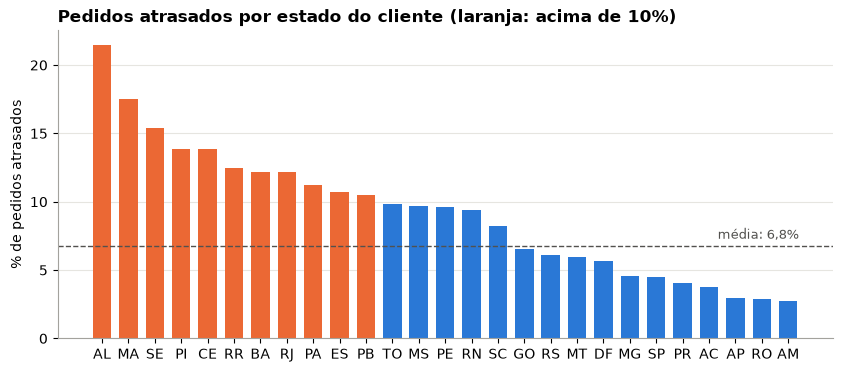

In [7]:
por_uf = entregues.groupby('customer_state').agg(pedidos=('order_id', 'size'),
                                                 atrasados=('atrasado', 'sum'),
                                                 pct_atraso=('atrasado', 'mean'),
                                                 prazo_mediano=('prazo', 'median'),
                                                 prazo_media=('prazo', 'mean'),
                                                 prazo_desvio=('prazo', 'std'),
                                                 pct_nota_1_2=('nota_ruim', 'mean'))
por_uf['cv_prazo'] = por_uf['prazo_desvio'] / por_uf['prazo_media']
por_uf['parte_dos_atrasos'] = por_uf['atrasados'] / por_uf['atrasados'].sum()
por_uf = por_uf.sort_values('pct_atraso', ascending=False)

print(por_uf[['pedidos', 'pct_atraso', 'parte_dos_atrasos', 'prazo_mediano', 'cv_prazo', 'pct_nota_1_2']].round(3))

media_brasil = entregues['atrasado'].mean() * 100
cores = [LARANJA if p > 0.10 else AZUL for p in por_uf['pct_atraso']]
plt.figure()
plt.bar(por_uf.index, por_uf['pct_atraso'] * 100, color=cores, width=0.7)
plt.axhline(media_brasil, color='#52514e', linewidth=1, linestyle='--')
plt.text(26.4, media_brasil + 0.5, f'média: {media_brasil:.1f}%'.replace('.', ','), ha='right', fontsize=9, color='#52514e')
plt.title('Pedidos atrasados por estado do cliente (laranja: acima de 10%)')
plt.ylabel('% de pedidos atrasados')
plt.show()

- As maiores taxas estão no Nordeste: Alagoas (21,5%), Maranhão (17,5%), Sergipe, Piauí, Ceará e Bahia, todos acima de 12%.
- O Rio de Janeiro tem 12,1% de atraso e é o segundo maior mercado (12.310 pedidos). Sozinho, responde por **23% de todos os atrasos**, quase o mesmo que SP (28%), que tem três vezes mais pedidos.
- Parte do Norte (Amazonas, Amapá, Rondônia e Acre) tem prazo mediano acima de 17 dias, mas atraso abaixo de 4%. A promessa desses estados já considera a distância.

Leitura: o atraso não depende só da distância, e sim de **a promessa estar ajustada à distância**. Onde a promessa é longa (esses estados do Norte), o atraso é raro; no Nordeste e no RJ, a promessa não acompanha o prazo real.

O coeficiente de variação fica entre 40% e 93%: em todos os estados o prazo é pouco previsível, inclusive em SP (77%), que tem o menor prazo mediano.

## 6.4.1 A distância em quilômetros acrescenta algo ao estado?

A tabela geolocation traz latitude e longitude por CEP, o que permite medir a distância real entre vendedor e cliente. Antes de usá-la no relatório, vale saber se ela muda alguma conclusão. **Hipótese:** se a distância em km for o que explica o atraso, pedidos mais longos atrasam mais **dentro de um mesmo estado**, e destinos à mesma distância de SP atrasam parecido.

Para testar, calculo a coordenada média de cada CEP (o CEP se repete cerca de 53 vezes na tabela) e a distância em linha reta (fórmula de *haversine*) entre o vendedor do primeiro item e o cliente.

In [8]:
geolocation = pd.read_csv('../data/raw/olist_geolocation_dataset.csv')
coord = geolocation.groupby('geolocation_zip_code_prefix')[['geolocation_lat', 'geolocation_lng']].mean()

dist = entregues.merge(customers[['customer_id', 'customer_zip_code_prefix']], on='customer_id')
dist = dist.merge(sellers[['seller_id', 'seller_zip_code_prefix']], on='seller_id')
dist = dist.join(coord, on='customer_zip_code_prefix').join(coord.add_suffix('_seller'), on='seller_zip_code_prefix')

lat1, lng1 = np.radians(dist['geolocation_lat']), np.radians(dist['geolocation_lng'])
lat2, lng2 = np.radians(dist['geolocation_lat_seller']), np.radians(dist['geolocation_lng_seller'])
a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lng2 - lng1) / 2) ** 2
dist['km'] = 6371 * 2 * np.arcsin(np.sqrt(a))
print(f"Pedidos sem coordenada: {dist['km'].isna().mean() * 100:.1f}%")

dist['faixa_km'] = pd.cut(dist['km'], [0, 100, 300, 600, 1000, 2000, 5000])
print('\nAtraso por faixa de distância')
print(dist.groupby('faixa_km', observed=True).agg(pedidos=('order_id', 'size'),
                                                 pct_atraso=('atrasado', 'mean'),
                                                 prazo_mediano=('prazo', 'median')).round(3))

saindo_sp = dist[dist['seller_state'] == 'SP']
print('\nSaindo de SP: destinos a distâncias parecidas')
print(saindo_sp[saindo_sp['customer_state'].isin(['RJ', 'PR', 'MG'])]
      .groupby('customer_state').agg(pedidos=('order_id', 'size'),
                                     km_mediano=('km', 'median'),
                                     pct_atraso=('atrasado', 'mean')).round(3))

print('\nSaindo de SP, dentro de cada estado: % de atraso por terço de distância')
for uf in ['SP', 'RJ', 'MG', 'BA']:
    destino = saindo_sp[saindo_sp['customer_state'] == uf]
    terco = pd.qcut(destino['km'], 3, labels=['perto', 'médio', 'longe'])
    print(uf, (destino.groupby(terco, observed=True)['atrasado'].mean() * 100).round(1).to_dict())

Pedidos sem coordenada: 0.5%

Atraso por faixa de distância
              pedidos  pct_atraso  prazo_mediano
faixa_km                                        
(0, 100]        17837       0.045          5.083
(100, 300]      13298       0.052          8.185
(300, 600]      31404       0.068         10.317
(600, 1000]     17850       0.071         12.507
(1000, 2000]     9721       0.096         15.365
(2000, 5000]     5589       0.121         18.241

Saindo de SP: destinos a distâncias parecidas
                pedidos  km_mediano  pct_atraso
customer_state                                 
MG                 7421     488.627       0.053
PR                 3111     419.244       0.044
RJ                 8141     383.355       0.142

Saindo de SP, dentro de cada estado: % de atraso por terço de distância
SP {'perto': 4.4, 'médio': 4.7, 'longe': 4.8}
RJ {'perto': 12.2, 'médio': 13.4, 'longe': 16.9}
MG {'perto': 6.0, 'médio': 5.7, 'longe': 4.1}
BA {'perto': 12.7, 'médio': 12.6, 'longe': 13.0

- No Brasil todo, a distância pesa: o atraso sobe de **4,5%** até 100 km para **12,1%** acima de 2.000 km, e o prazo mediano vai de 5 para 18 dias.
- Mas o destino pesa mais que a distância. Saindo de SP, o Rio de Janeiro fica a 383 km e atrasa **14,2%**; o Paraná, a 419 km, atrasa **4,4%**; Minas Gerais, a 489 km, 5,3%.
- Dentro de um mesmo estado, a distância quase não muda o atraso: SP fica entre 4,4% e 4,8%, BA entre 12,6% e 13,0%, e em MG os mais longe atrasam menos. Só no RJ o interior atrasa mais (17% contra 12%), e mesmo o RJ "perto" atrasa o dobro de MG.

**Decisão:** a distância em km não acrescenta nada ao estado do cliente. O relatório usa estado, que é também o nível em que a Olist negocia transporte e define o prazo prometido. A tabela geolocation fica só neste teste. A comparação RJ x PR x MG reforça a leitura do 6.4: o problema é a rota e a promessa, não a distância.

## 6.5 O atraso vem do vendedor ou da transportadora?

A jornada tem duas partes: o vendedor posta o pedido (compra → postagem) e a transportadora entrega (postagem → entrega). A tabela de itens traz o **prazo limite para o vendedor postar** (`shipping_limit_date`).

**Hipótese:** os atrasos vêm principalmente do vendedor que posta depois do limite. Para testar, comparo o tempo de cada etapa nos pedidos no prazo e nos atrasados. Pela decisão do notebook 01, excluo os pedidos com datas fora de ordem, porque a data de postagem deles não é confiável.

In [9]:
postagem = entregues['order_delivered_carrier_date']
fora_de_ordem = ((postagem < entregues['order_purchase_timestamp'])
                 | (postagem < entregues['order_approved_at'])
                 | (entregues['order_delivered_customer_date'] < postagem))
etapas = entregues[postagem.notna() & ~fora_de_ordem].copy()

etapas['dias_vendedor'] = (etapas['order_delivered_carrier_date'] - etapas['order_purchase_timestamp']).dt.total_seconds() / 86400
etapas['dias_transportadora'] = (etapas['order_delivered_customer_date'] - etapas['order_delivered_carrier_date']).dt.total_seconds() / 86400
etapas['postou_atrasado'] = etapas['order_delivered_carrier_date'] > etapas['limite_postagem']

print(f'Pedidos com etapas confiáveis: {len(etapas):,}')
print()
print('Mediana de dias por etapa:')
print(etapas.groupby('atrasado')[['dias_vendedor', 'dias_transportadora']].median().round(1))
print()
print('Atrasados em que o vendedor postou depois do limite:')
print(etapas.loc[etapas['atrasado'], 'postou_atrasado'].value_counts())

Pedidos com etapas confiáveis: 94,833

Mediana de dias por etapa:
          dias_vendedor  dias_transportadora
atrasado                                    
False               2.2                  7.0
True                3.5                 26.2

Atrasados em que o vendedor postou depois do limite:
postou_atrasado
False    4695
True     1811
Name: count, dtype: int64


- Nos pedidos atrasados, o vendedor leva 3,5 dias para postar (contra 2,2 dias nos pedidos no prazo). A transportadora leva **26,2 dias** (contra 7,0).
- Só **28%** dos pedidos atrasados tiveram postagem depois do limite. Em 72%, o vendedor cumpriu o prazo dele.

A hipótese não se sustenta: a maior parte do atraso acontece no transporte, depois que o vendedor já postou.

## 6.6 Os vendedores concentram o valor vendido ou as notas ruins?

O vendedor não é o principal responsável pelo atraso, mas pode explicar as notas ruins de pedidos entregues no prazo. Primeiro, vejo quanto do valor vendido está concentrado nos maiores vendedores.

In [10]:
vendas = orders[orders['order_purchase_timestamp'].between('2017-01-01', '2018-08-31 23:59:59')
                & ~orders['order_status'].isin(['canceled', 'unavailable'])]
itens_vendidos = items[items['order_id'].isin(vendas['order_id'])].copy()
itens_vendidos['valor'] = itens_vendidos['price'] + itens_vendidos['freight_value']

vendido_vendedor = itens_vendidos.groupby('seller_id')['valor'].sum().sort_values(ascending=False)
top_20 = int(len(vendido_vendedor) * 0.2)
print(f'Vendedores com venda no recorte: {len(vendido_vendedor):,}')
print(f'Valor vendido pelos 20% maiores ({top_20} vendedores): {vendido_vendedor.head(top_20).sum() / vendido_vendedor.sum() * 100:.0f}%')

Vendedores com venda no recorte: 3,029
Valor vendido pelos 20% maiores (605 vendedores): 82%


Os **20% maiores vendedores (605) fazem 82% do valor vendido**. As vendas estão concentradas.

**Hipótese:** as notas ruins dos pedidos no prazo também estão concentradas em poucos vendedores ruins. Se for assim, a parte desses vendedores nas notas ruins é bem maior que a parte deles nos pedidos. Para testar, ordeno os vendedores pelo número de notas 1 e 2 em pedidos no prazo e comparo as duas partes nos 100 primeiros.

In [11]:
no_prazo = entregues[~entregues['atrasado']]
por_vendedor = no_prazo.groupby('seller_id').agg(pedidos=('order_id', 'size'),
                                                 notas_ruins=('nota_ruim', 'sum'))
por_vendedor = por_vendedor.sort_values('notas_ruins', ascending=False)
top_100 = por_vendedor.head(100)

print(f'Os 100 vendedores com mais notas ruins têm {top_100["notas_ruins"].sum() / por_vendedor["notas_ruins"].sum() * 100:.0f}% das notas ruins')
print(f'e {top_100["pedidos"].sum() / por_vendedor["pedidos"].sum() * 100:.0f}% dos pedidos no prazo')

Os 100 vendedores com mais notas ruins têm 51% das notas ruins
e 42% dos pedidos no prazo


Os 100 vendedores com mais notas ruins têm **51% das notas ruins e 42% dos pedidos**. A diferença existe, mas é pequena: são, em grande parte, os vendedores que mais vendem.

A hipótese não se sustenta. As notas ruins acompanham o volume, e não se concentram em um pequeno grupo de vendedores ruins.

## 6.7 Pedidos com vários itens

No notebook 02, 10% dos pedidos tinham mais de um item. **Hipótese:** pedidos com vários itens recebem notas piores mesmo no prazo, porque têm mais chance de chegar incompletos. Para testar, separo os pedidos no prazo em quatro grupos e comparo a nota.

In [12]:
no_prazo = entregues[~entregues['atrasado']].copy()
no_prazo['tipo'] = 'Um item'
no_prazo.loc[(no_prazo['itens'] > 1) & (no_prazo['produtos'] == 1), 'tipo'] = 'Mesmo produto repetido'
no_prazo.loc[(no_prazo['produtos'] > 1) & (no_prazo['vendedores'] == 1), 'tipo'] = 'Vários produtos, um vendedor'
no_prazo.loc[no_prazo['vendedores'] > 1, 'tipo'] = 'Vários vendedores'

por_tipo = no_prazo.groupby('tipo').agg(pedidos=('order_id', 'size'),
                                        pct_nota_1_2=('nota_ruim', 'mean'),
                                        notas_ruins=('nota_ruim', 'sum'))
print(por_tipo.round(3))
print()
print(f'Parte das notas ruins no prazo vinda de pedidos com mais de um item: '
      f'{1 - por_tipo.loc["Um item", "notas_ruins"] / por_tipo["notas_ruins"].sum():.0%}')

                              pedidos  pct_nota_1_2  notas_ruins
tipo                                                            
Mesmo produto repetido           6030         0.204         1231
Um item                         80576         0.075         6034
Vários produtos, um vendedor     1807         0.220          398
Vários vendedores                1259         0.464          584



Parte das notas ruins no prazo vinda de pedidos com mais de um item: 27%


- Pedidos com um item: 7,5% de notas 1 e 2.
- Pedidos com vários itens: entre 20% e 22% de notas 1 e 2 com um vendedor, e **46%** quando há vários vendedores, mesmo entregues no prazo.
- Esses pedidos são 10% dos entregues no prazo, mas geram **27% das notas ruins** desse grupo.

A nota pior se confirma. Falta testar o motivo. Os comentários das avaliações trazem o relato do cliente; com str.contains() procuro, nos comentários das notas 1 e 2, palavras que indicam falta de produto ("falt", "incomplet", "não recebi", "apenas", "somente").

In [13]:
ruins = no_prazo[no_prazo['nota_ruim'] & no_prazo['review_comment_message'].notna()].copy()
texto = ruins['review_comment_message'].str.lower()
ruins['fala_de_falta'] = texto.str.contains('falt|incomplet|não recebi|nao recebi|apenas|somente')

(ruins.groupby('tipo')['fala_de_falta'].mean() * 100).round(0)

tipo
Mesmo produto repetido          45.0
Um item                         13.0
Vários produtos, um vendedor    53.0
Vários vendedores               60.0
Name: fala_de_falta, dtype: float64

- Nas notas ruins de pedidos com vários itens, entre **45% e 60%** dos comentários falam de falta ou de não recebimento; o maior valor é o dos pedidos com vários vendedores.
- Nos pedidos de um item, são **13%**.

Leitura: a hipótese se sustenta. Uma parte relevante das notas ruins no prazo vem de entregas incompletas: o pedido consta como entregue, mas falta parte dos itens. O problema cresce quando o pedido tem mais de um vendedor, porque cada vendedor envia separado. O resultado é compatível com a análise de comentários do notebook 03 (item 4.9), em que a entrega incompleta aparece entre os temas mais citados das notas 1 e 2.

## 7.1 Qualidade da tabela de produtos

In [14]:
print('Produtos distintos:', products['product_id'].nunique())
print('Linhas idênticas:', products.duplicated().sum())
print('Itens sem produto:', (~items['product_id'].isin(products['product_id'])).sum())
print()
print(products.isnull().sum())

Produtos distintos: 32951
Linhas idênticas: 0
Itens sem produto: 0

product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64


- Um produto por linha, sem duplicatas e sem itens órfãos.
- **610 produtos** não têm categoria, e os mesmos 610 não têm nome, descrição e fotos: é um cadastro incompleto, e não falhas espalhadas.
- 2 produtos sem peso e medidas.

Confiro o peso dos produtos sem categoria nas vendas e se todas as categorias têm tradução.

In [15]:
sem_categoria = products.loc[products['product_category_name'].isnull(), 'product_id']
print(f'Valor vendido de produtos sem categoria: {itens_vendidos[itens_vendidos["product_id"].isin(sem_categoria)]["valor"].sum() / itens_vendidos["valor"].sum() * 100:.1f}%')

categorias = set(products['product_category_name'].dropna())
print('Categorias nos produtos:', len(categorias))
print('Categorias sem tradução:', categorias - set(traducao['product_category_name']))

Valor vendido de produtos sem categoria: 1.3%
Categorias nos produtos: 73
Categorias sem tradução: {'pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos'}


- Os produtos sem categoria somam **1,3% do valor vendido**.
- São 73 categorias, e 2 não têm tradução (`pc_gamer` e `portateis_cozinha_e_preparadores_de_alimentos`).

**Decisão:** produtos sem categoria entram como "sem categoria". Como o relatório é em português, uso os nomes originais e não uso a tabela de tradução, o que também elimina o problema das duas categorias faltantes.

## 7.2 Valor vendido por categoria

Parte das 10 maiores categorias: 62%


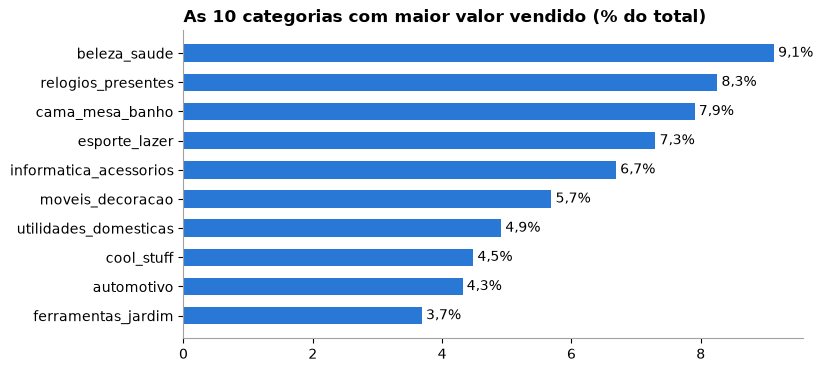

In [16]:
itens_vendidos = itens_vendidos.merge(products[['product_id', 'product_category_name']], on='product_id', how='left')
itens_vendidos['categoria'] = itens_vendidos['product_category_name'].fillna('sem categoria')

vendido_categoria = itens_vendidos.groupby('categoria')['valor'].sum().sort_values(ascending=False)
parte = vendido_categoria / vendido_categoria.sum() * 100
print(f'Parte das 10 maiores categorias: {parte.head(10).sum():.0f}%')

top10 = parte.head(10).sort_values()
plt.figure(figsize=(8, 4))
barras = plt.barh(top10.index, top10.values, color=AZUL, height=0.6)
plt.bar_label(barras, labels=[f'{v:.1f}%'.replace('.', ',') for v in top10.values], padding=3)
plt.grid(False)
plt.title('As 10 categorias com maior valor vendido (% do total)')
plt.show()

- As **10 maiores categorias fazem 62% do valor vendido**, e nenhuma passa de 10%: a Olist é bem diversificada.
- Lideram beleza e saúde (9,1%), **relógios e presentes** (8,3%) e cama, mesa e banho (7,9%).

## 7.3 Notas ruins por categoria

Com as vendas espalhadas, uma categoria problemática pesaria pouco. Mesmo assim, comparo as categorias com pelo menos 500 pedidos entregues no prazo, pela proporção de notas 1 e 2, para ver se alguma destoa.

In [17]:
primeiro_produto = items.drop_duplicates(subset='order_id')[['order_id', 'product_id']]
cat_no_prazo = (entregues[~entregues['atrasado']]
                .merge(primeiro_produto, on='order_id')
                .merge(products[['product_id', 'product_category_name']], on='product_id', how='left'))

por_categoria = cat_no_prazo.groupby('product_category_name').agg(pedidos=('order_id', 'size'),
                                                                 pct_nota_1_2=('nota_ruim', 'mean'))
por_categoria = por_categoria[por_categoria['pedidos'] >= 500].sort_values('pct_nota_1_2', ascending=False)
print(por_categoria.round(3).head(5))
print('...')
print(por_categoria.round(3).tail(3))

                        pedidos  pct_nota_1_2
product_category_name                        
moveis_escritorio          1139         0.180
cama_mesa_banho            8473         0.117
moveis_decoracao           5720         0.113
informatica_acessorios     6072         0.113
telefonia                  3778         0.108


...
                       pedidos  pct_nota_1_2
product_category_name                       
instrumentos_musicais      561         0.064
papelaria                 2099         0.061
malas_acessorios           965         0.055


- A maioria das categorias fica entre **6% e 12%** de notas 1 e 2 em pedidos no prazo.
- Móveis de escritório destoa, com **18%**, seguida de cama, mesa e banho e móveis e decoração (cerca de 11%).

Leitura: a categoria pesa pouco nas notas ruins, com exceção de móveis de escritório, que fica no radar como categoria de risco.

## Resumo de vendedores e produtos

| # | Verificação | O que os dados mostraram | Decisão |
|---|---|---|---|
| 6.2 | Qualidade dos vendedores | sem vazios, duplicatas ou órfãos; 1,3% dos pedidos com mais de um vendedor | vendedor do primeiro item para rotas |
| 6.2 | Origem | 71% dos pedidos saem de SP | |
| 6.3 | Distância | entre estados: 8,1% de atraso, contra 4,5% no mesmo estado | |
| 6.4 | Estado do cliente | Nordeste com as maiores taxas; RJ com 12% e 23% dos atrasos; Norte com promessa longa e pouco atraso | |
| 6.4.1 | Distância em km | dentro do estado a distância quase não muda o atraso; RJ (383 km) atrasa 14%, PR (419 km) 4% e MG (489 km) 5% | estado basta; geolocation fora do relatório |
| 6.5 | Etapa do atraso | transporte leva 26 dias nos atrasados; 72% dos atrasados foram postados no prazo | atraso é do transporte |
| 6.6 | Vendedores | 20% fazem 82% do valor vendido; notas ruins acompanham o volume | |
| 6.7 | Pedidos com vários itens | 27% das notas ruins no prazo; 45% a 60% dos comentários falam de falta (13% em pedidos de um item) | entrega incompleta como causa de nota ruim |
| 7.1 | Qualidade dos produtos | 610 sem categoria (1,3% do valor vendido); 2 categorias sem tradução | "sem categoria"; nomes em português, sem a tradução |
| 7.2 | Valor vendido por categoria | 10 maiores fazem 62%, nenhuma acima de 10% | |
| 7.3 | Nota por categoria | entre 6% e 12% de notas ruins; móveis de escritório com 18% | categoria de risco |

**Resposta à pergunta:**
- Os atrasos estão no **transporte entre estados**, com destaque para o Rio de Janeiro (volume alto e 12% de atraso) e o Nordeste (as maiores taxas). O vendedor cumpre o prazo de postagem na maioria dos pedidos atrasados.
- As **notas ruins no prazo** não estão em poucos vendedores nem em categorias específicas. Uma causa clara são as entregas incompletas de pedidos com vários itens, principalmente quando há mais de um vendedor.